# 1. Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Loading and Previewing the Cleaned Dataset

In [2]:
df = pd.read_csv("../Dataset/Processed/Customer_Churn_Cleaned.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 3. Checking Dataset Dimensions and Data Types

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nData Types:")
print(df.dtypes)

Rows: 7043
Columns: 21

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [4]:
df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


# 4. Overall Customer Churn Distribution

In [5]:
churn_counts = df["Churn"].value_counts()

print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


# 5. Analyzing Customer Churn Percentage

In [6]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


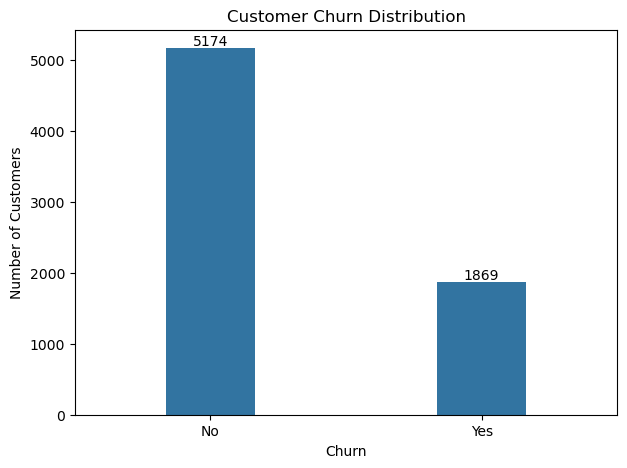

In [52]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Churn", width=0.33)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

# 6. Analyzing Churn by Contract Type

In [8]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


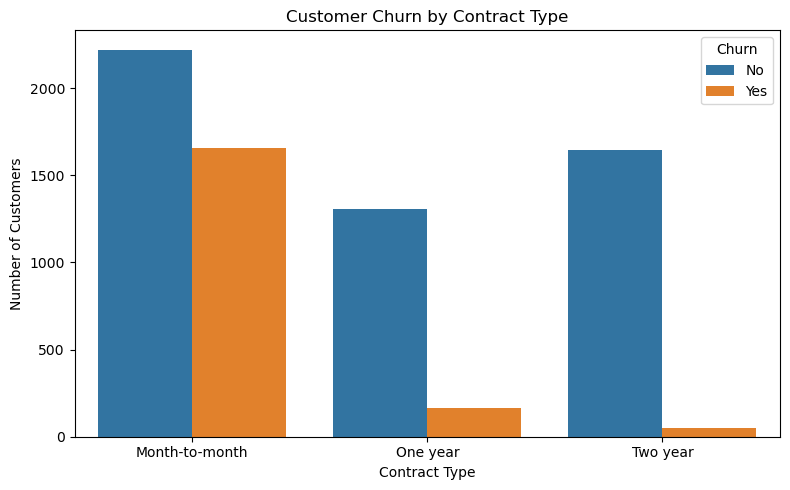

In [33]:
# Churn by Contract Type

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.tight_layout()
plt.show()

# 7. Analyzing Churn by Internet Service

In [10]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


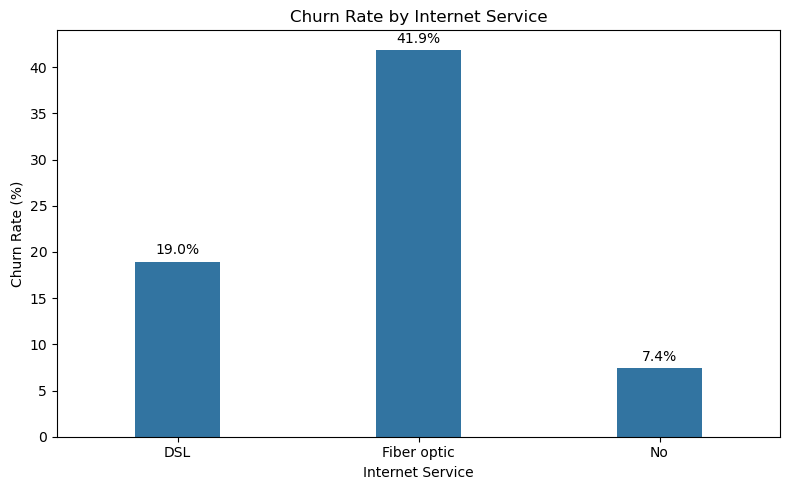

In [54]:
# Churn Rate by Internet Service

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=internet_churn.reset_index(),
    x="InternetService",
    y="Yes", width=0.35
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

# Add values on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

# 8. Analyzing Churn by Payment Method

In [12]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


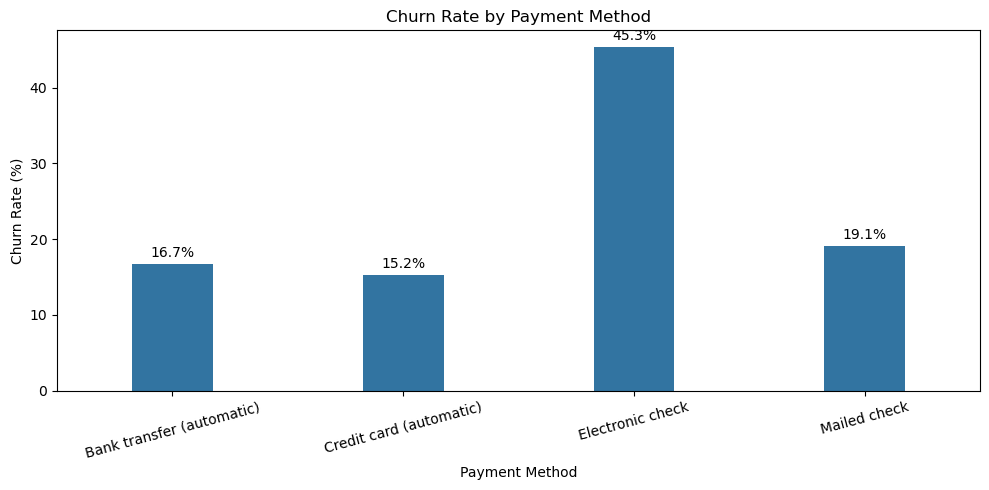

In [55]:
# Churn Rate by Payment Method

payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=payment_churn.reset_index(),
    x="PaymentMethod",
    y="Yes", width=0.35
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

# 9. Analyzing Churn by Paperless Billing

In [14]:
paperless_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

print(paperless_churn.round(2))

Churn                No    Yes
PaperlessBilling              
No                83.67  16.33
Yes               66.43  33.57


# 10. Analyzing Churn by Technical Support

In [15]:
techsupport_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print(techsupport_churn.round(2))

Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


# 11. Analyzing Churn by Online Security

In [16]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print(security_churn.round(2))

Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61


# 12. Analyzing Churn by Online Backup

In [17]:
backup_churn = pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

print(backup_churn.round(2))

Churn                   No    Yes
OnlineBackup                     
No                   60.07  39.93
No internet service  92.60   7.40
Yes                  78.47  21.53


# 13. Analyzing Churn by Device Protection

In [18]:
device_churn = pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

print(device_churn.round(2))

Churn                   No    Yes
DeviceProtection                 
No                   60.87  39.13
No internet service  92.60   7.40
Yes                  77.50  22.50


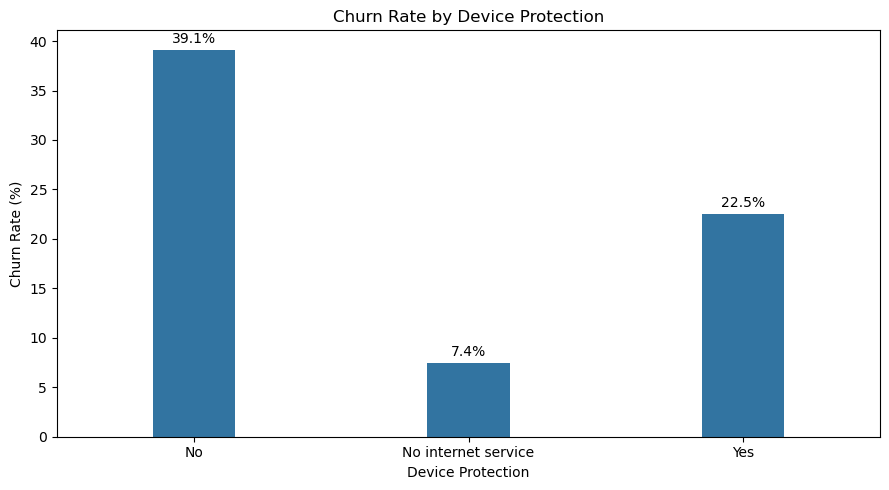

In [56]:
# Churn Rate by Device Protection

device_churn = pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=device_churn.reset_index(),
    x="DeviceProtection",
    y="Yes", width=0.3
)

plt.title("Churn Rate by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Churn Rate (%)")

# Add values on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

# 14. Analyzing Churn by Senior Citizen Status

In [20]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print(senior_churn.round(2))

Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68


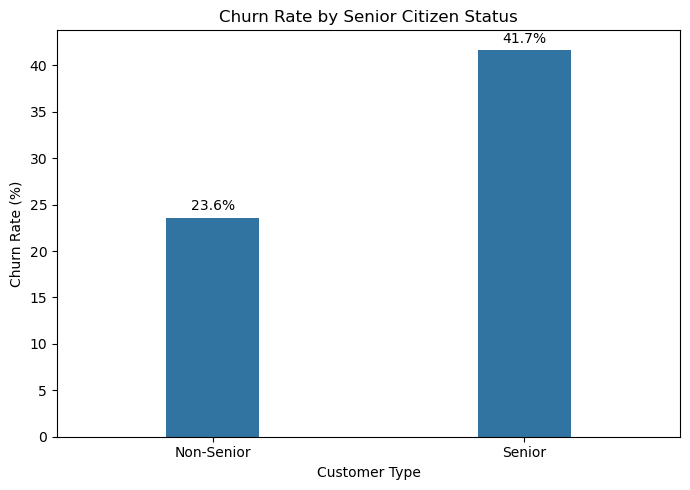

In [44]:
# Churn Rate by Senior Citizen Status

senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

senior_churn.index = senior_churn.index.map({
    0: "Non-Senior",
    1: "Senior"
})

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=senior_churn.reset_index(),
    x="SeniorCitizen",
    y="Yes", width=0.3
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Customer Type")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

# 15. Analyzing Churn by Partner Status

In [22]:
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

print(partner_churn.round(2))

Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66


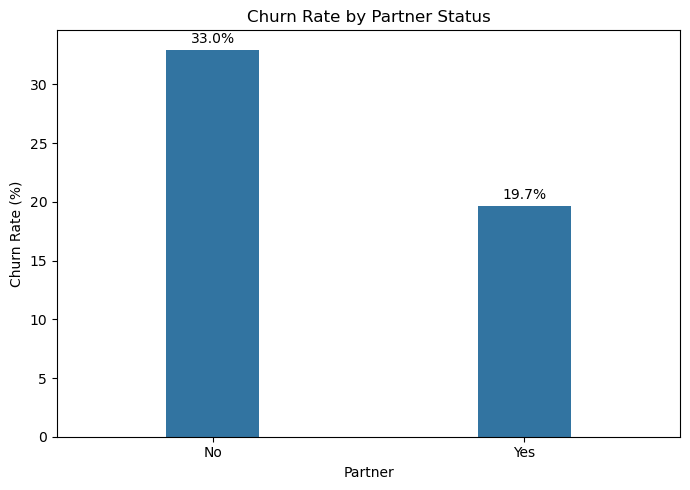

In [45]:
# Churn Rate by Partner Status

partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=partner_churn.reset_index(),
    x="Partner",
    y="Yes", width=0.3
)

plt.title("Churn Rate by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

# 16. Analyzing Churn by Dependents Status

In [24]:
dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

print(dependents_churn.round(2))

Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45


# 17. Comparing Monthly Charges by Churn Status

In [25]:
monthly_charges_churn = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print(monthly_charges_churn)

       count   mean  median    min     max
Churn                                     
No      5174  61.27   64.43  18.25  118.75
Yes     1869  74.44   79.65  18.85  118.35


# 18. Comparing Customer Tenure by Churn Status

In [26]:
tenure_churn = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print(tenure_churn)

       count   mean  median  min  max
Churn                                
No      5174  37.57    38.0    0   72
Yes     1869  17.98    10.0    1   72


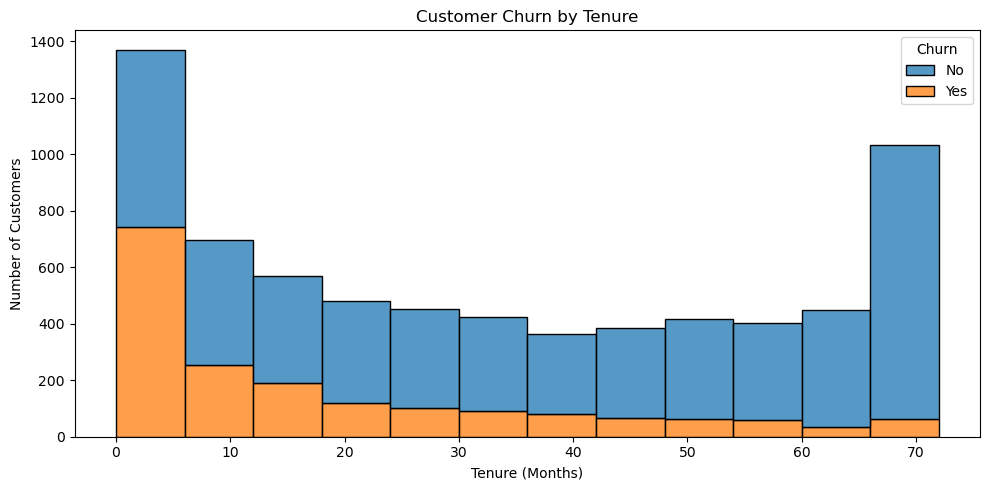

In [27]:
# Churn by Tenure

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=12,
    multiple='stack'
)

plt.title('Customer Churn by Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()